In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import joblib
import pandas as pd

# Load test data
data_folder = "/content/drive/MyDrive/AI_NIDS_Dataset/Task4_Output"

X_test = pd.read_parquet(os.path.join(data_folder, "X_test.parquet"))
y_test = pd.read_parquet(os.path.join(data_folder, "y_test.parquet"))["Label"]

# Load trained models
model_folder = "/content/drive/MyDrive/AI_NIDS_Dataset/Task5_Output/Trained_Models"

lightgbm_model = joblib.load(
    os.path.join(model_folder, "LightGBM_Model.pkl")
)

xgboost_model = joblib.load(
    os.path.join(model_folder, "XGBoost_Model.pkl")
)

random_forest_model = joblib.load(
    os.path.join(model_folder, "Random_Forest_Model.pkl")
)

label_encoder = joblib.load(
    os.path.join(model_folder, "Label_Encoder.pkl")
)

print("Test data shape:", X_test.shape)
print("Test labels shape:", y_test.shape)
print("Number of classes:", y_test.nunique())
print("All three models loaded successfully!")

Test data shape: (385896, 78)
Test labels shape: (385896,)
Number of classes: 15
All three models loaded successfully!


In [ ]:
# Generate LightGBM predictions
y_lightgbm_test_pred = lightgbm_model.predict(X_test)

# Generate XGBoost predictions
y_xgb_test_encoded = xgboost_model.predict(X_test)
y_xgboost_test_pred = label_encoder.inverse_transform(
    y_xgb_test_encoded.astype(int)
)

# Generate Random Forest predictions
y_rf_test_pred = random_forest_model.predict(X_test)

print("All three models generated test predictions successfully!")

print("\nLightGBM predictions:", len(y_lightgbm_test_pred))
print("XGBoost predictions:", len(y_xgboost_test_pred))
print("Random Forest predictions:", len(y_rf_test_pred))

All three models generated test predictions successfully!

LightGBM predictions: 385896
XGBoost predictions: 385896
Random Forest predictions: 385896


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models_predictions = {
    "LightGBM": y_lightgbm_test_pred,
    "XGBoost": y_xgboost_test_pred,
    "Random Forest": y_rf_test_pred
}

test_results = []

for model_name, predictions in models_predictions.items():

    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    })

test_comparison_df = pd.DataFrame(test_results)

print("Final Test Performance Comparison:")
display(test_comparison_df)

Final Test Performance Comparison:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,LightGBM,0.997429,0.729248,0.768412,0.745115,0.997847
1,XGBoost,0.998774,0.895505,0.868823,0.873390,0.998795
2,Random Forest,0.998279,0.865719,0.818991,0.835402,0.998244


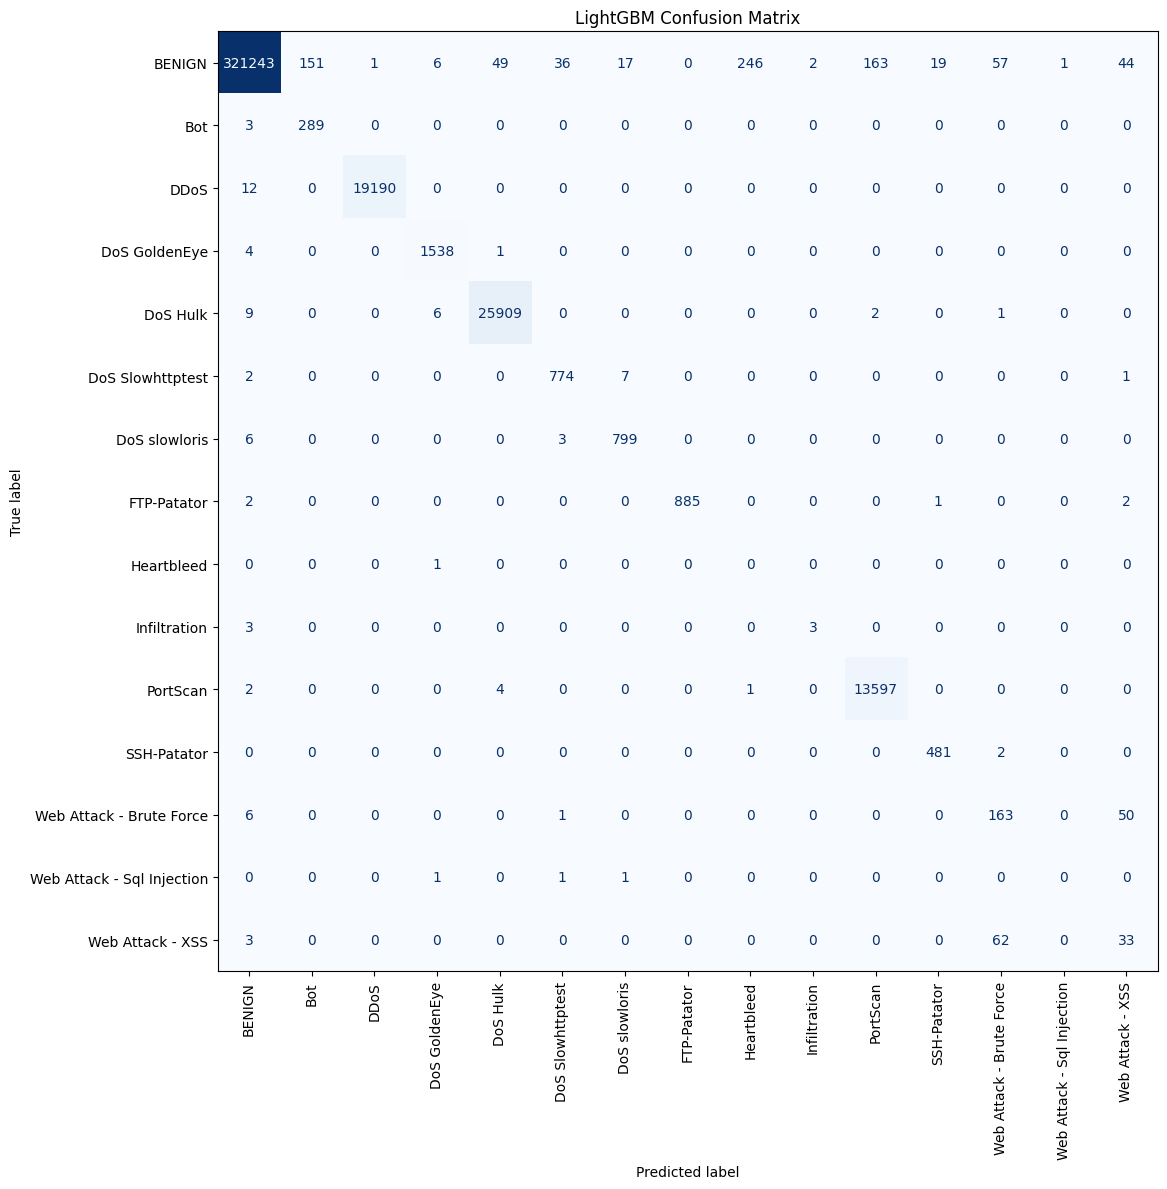

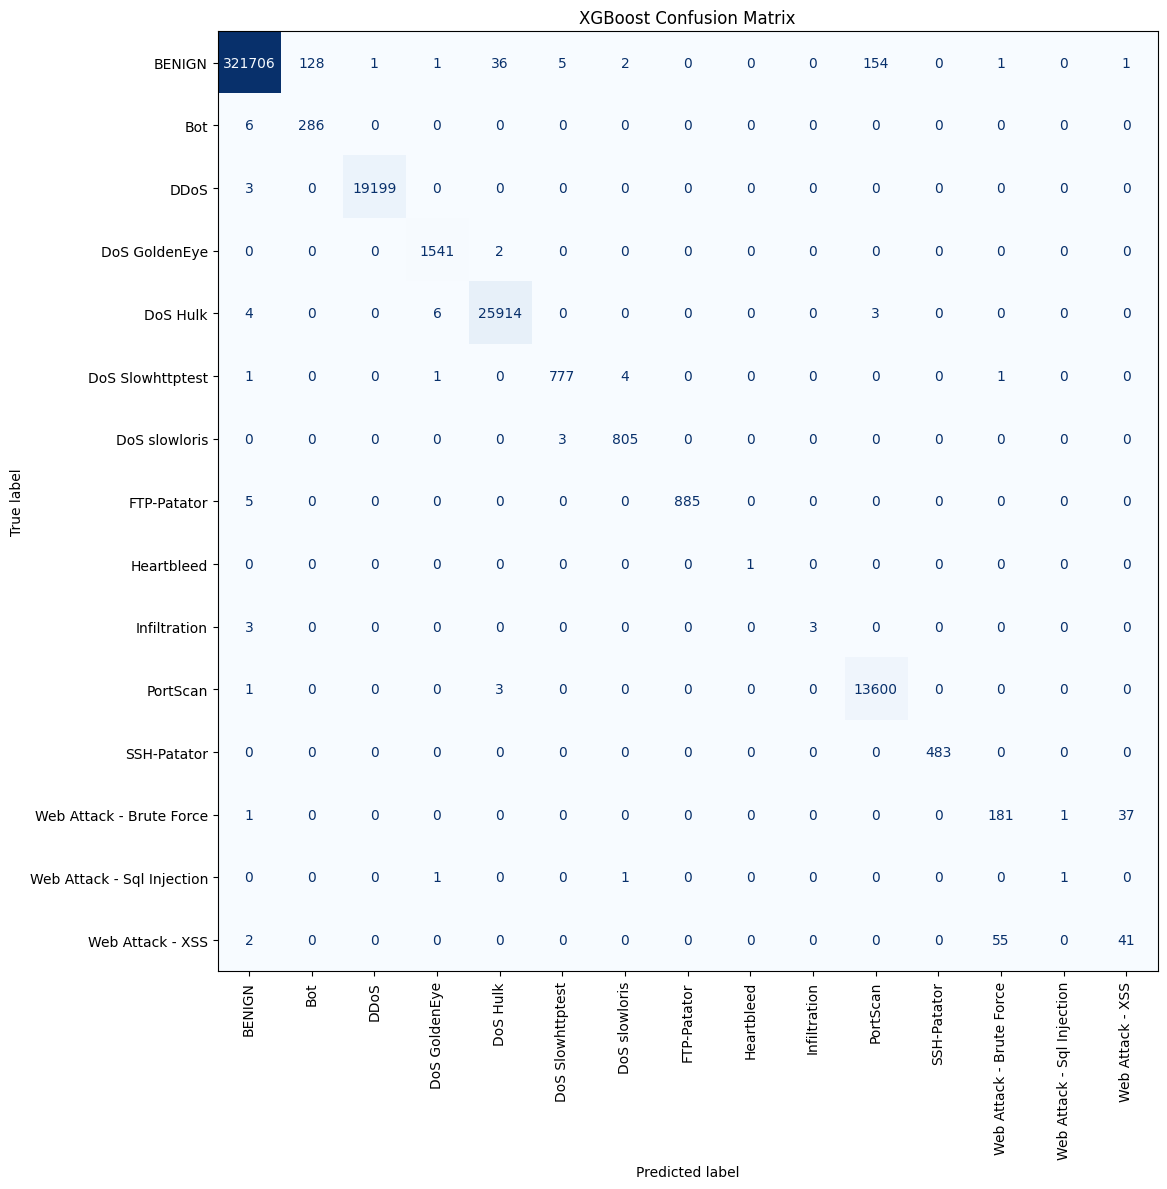

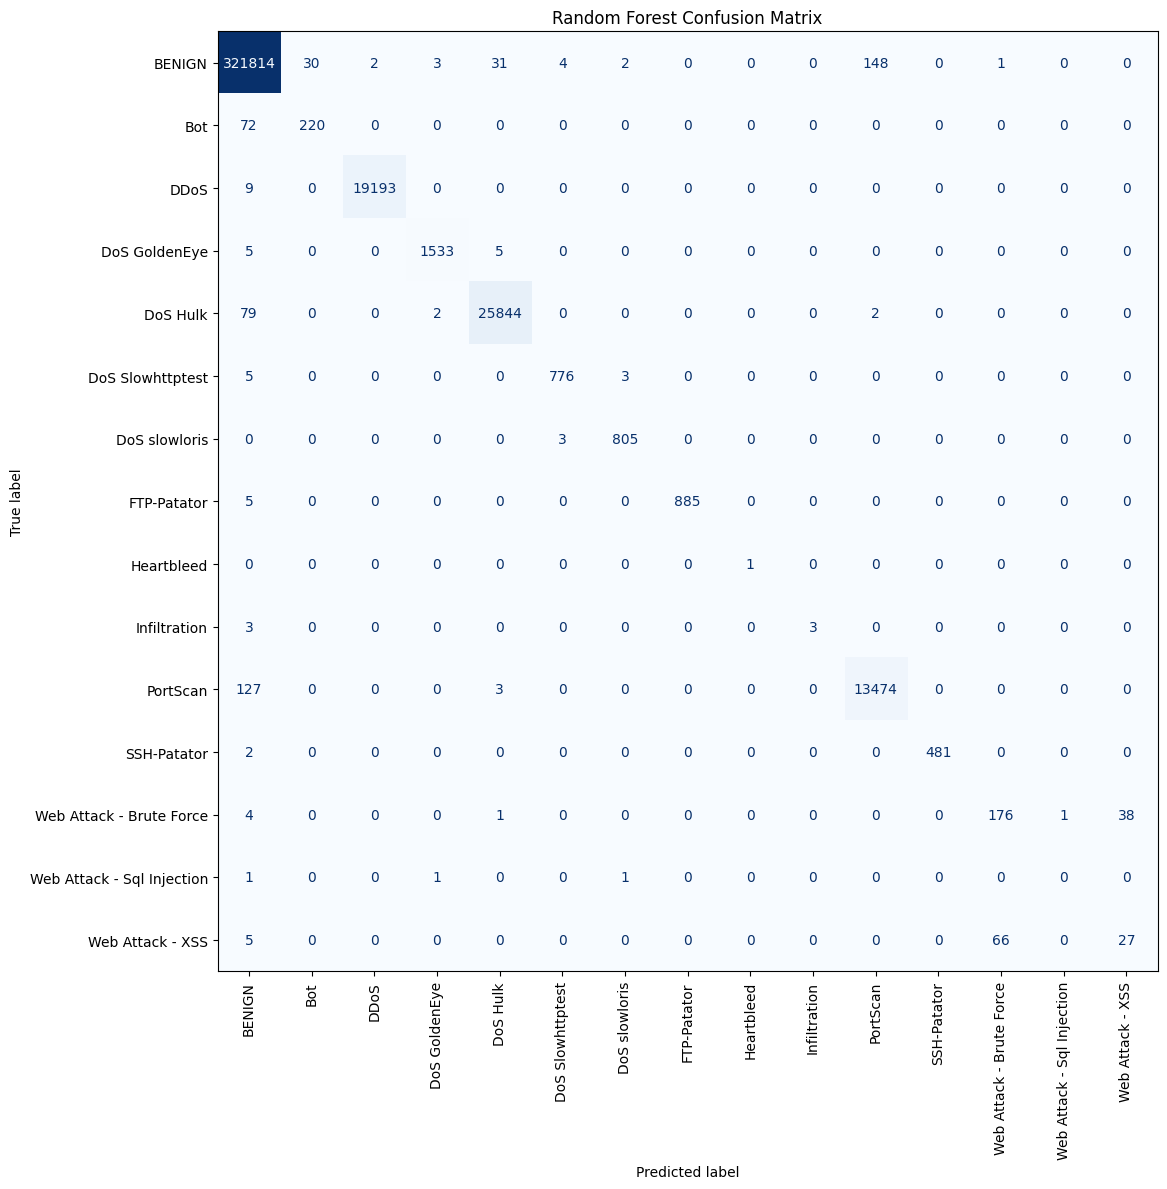

All three confusion matrices saved successfully!


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import os

output_folder = "/content/drive/MyDrive/AI_NIDS_Dataset/Task6_Output"
os.makedirs(output_folder, exist_ok=True)

models_predictions = {
    "LightGBM": y_lightgbm_test_pred,
    "XGBoost": y_xgboost_test_pred,
    "Random Forest": y_rf_test_pred
}

for model_name, predictions in models_predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=label_encoder.classes_
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=label_encoder.classes_
    )

    fig, ax = plt.subplots(figsize=(15, 12))

    display.plot(
        ax=ax,
        xticks_rotation=90,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    plt.title(f"{model_name} Confusion Matrix")
    plt.tight_layout()

    plt.savefig(
        os.path.join(output_folder, f"{model_name}_Confusion_Matrix.png"),
        dpi=300
    )

    plt.show()
    plt.close(fig)

print("All three confusion matrices saved successfully!")

In [ ]:
import os

comparison_path = os.path.join(
    output_folder,
    "Final_Test_Comparison.csv"
)

test_comparison_df.to_csv(comparison_path, index=False)

print("Final test comparison saved successfully!")
display(test_comparison_df)

Final test comparison saved successfully!


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [ ]:
from IPython.display import display as show_table

show_table(test_comparison_df)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,LightGBM,0.997429,0.729248,0.768412,0.745115,0.997847
1,XGBoost,0.998774,0.895505,0.868823,0.873390,0.998795
2,Random Forest,0.998279,0.865719,0.818991,0.835402,0.998244


In [ ]:
from sklearn.metrics import classification_report

print("LightGBM Classification Report:")
print(classification_report(y_test, y_lightgbm_test_pred, zero_division=0))

print("\nXGBoost Classification Report:")
print(classification_report(y_test, y_xgboost_test_pred, zero_division=0))

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, y_rf_test_pred, zero_division=0))

LightGBM Classification Report:
                            precision    recall  f1-score   support

                    BENIGN       1.00      1.00      1.00    322035
                       Bot       0.66      0.99      0.79       292
                      DDoS       1.00      1.00      1.00     19202
             DoS GoldenEye       0.99      1.00      0.99      1543
                  DoS Hulk       1.00      1.00      1.00     25927
          DoS Slowhttptest       0.95      0.99      0.97       784
             DoS slowloris       0.97      0.99      0.98       808
               FTP-Patator       1.00      0.99      1.00       890
                Heartbleed       0.00      0.00      0.00         1
              Infiltration       0.60      0.50      0.55         6
                  PortScan       0.99      1.00      0.99     13604
               SSH-Patator       0.96      1.00      0.98       483
  Web Attack - Brute Force       0.57      0.74      0.65       220
Web Attack - Sq

In [ ]:
import os
import json
from sklearn.metrics import classification_report

reports = {
    "LightGBM": y_lightgbm_test_pred,
    "XGBoost": y_xgboost_test_pred,
    "Random_Forest": y_rf_test_pred
}

for model_name, predictions in reports.items():
    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    file_path = os.path.join(
        output_folder,
        f"{model_name}_Classification_Report.json"
    )

    with open(file_path, "w") as file:
        json.dump(report, file, indent=4)

    print(f"{model_name} classification report saved successfully!")

LightGBM classification report saved successfully!
XGBoost classification report saved successfully!
Random_Forest classification report saved successfully!


In [ ]:
import os

print("Task 6 Output Files:\n")

for file_name in sorted(os.listdir(output_folder)):
    file_path = os.path.join(output_folder, file_name)

    if os.path.isfile(file_path):
        size_kb = os.path.getsize(file_path) / 1024
        print(f"{file_name} — {size_kb:.2f} KB")

Task 6 Output Files:

Final_Test_Comparison.csv — 0.37 KB
LightGBM_Classification_Report.json — 2.78 KB
LightGBM_Confusion_Matrix.png — 403.66 KB
Random Forest_Confusion_Matrix.png — 398.52 KB
Random_Forest_Classification_Report.json — 2.74 KB
XGBoost_Classification_Report.json — 2.75 KB
XGBoost_Confusion_Matrix.png — 393.38 KB
